# Foundations of R Software — Week 12: Solved Examples
**Based on the uploaded `FRS_LecNotesWeek12.pdf` (Lectures 50–53).**

This notebook contains the examples from the notes: component bar plots, pie charts, combined graphics, histograms, bivariate/matrix scatter plots, smooth curves, 3D plots, perspective plots, and the three R programming examples.

## Lecture 50 — Component bar diagram

A component (subdivided) bar diagram displays totals divided into component values. In the notes, each column of the matrix represents a shop, and each row represents a day.

In [1]:
cust <- matrix(
  nrow = 4, ncol = 3,
  data = c(2, 20, 30,
           26, 53, 40,
           42, 15, 25,
           30, 75, 100),
  byrow = TRUE
)
rownames(cust) <- paste("Day", 1:4)
colnames(cust) <- paste("Shop", 1:3)
cust

,Shop 1,Shop 2,Shop 3
Day 1,2,20,30
Day 2,26,53,40
Day 3,42,15,25
Day 4,30,75,100


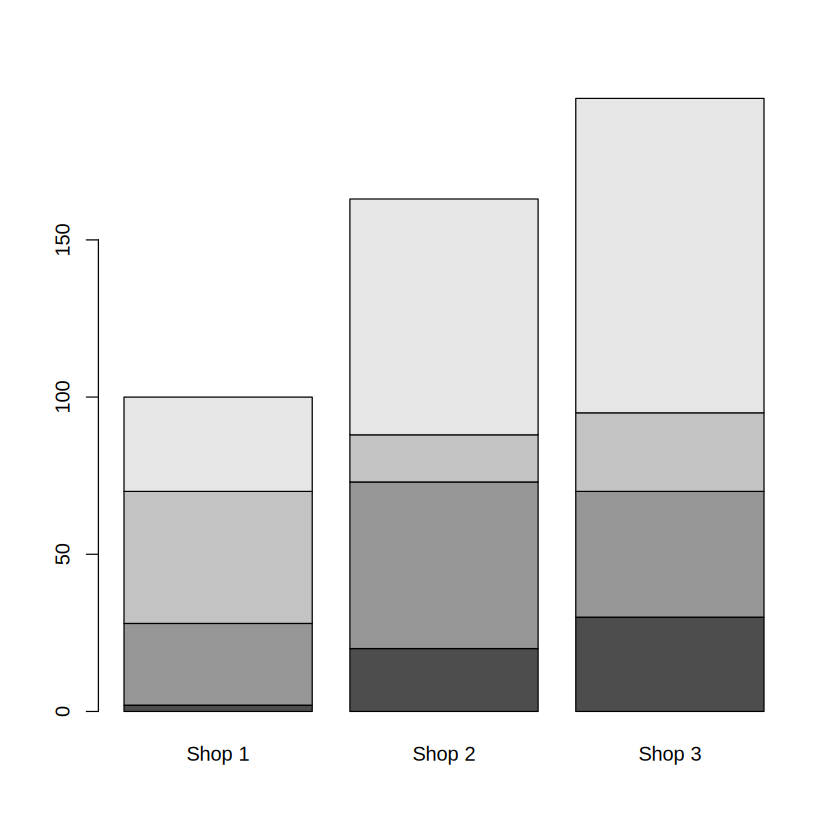

In [2]:
# Basic component bar plot
barplot(cust)

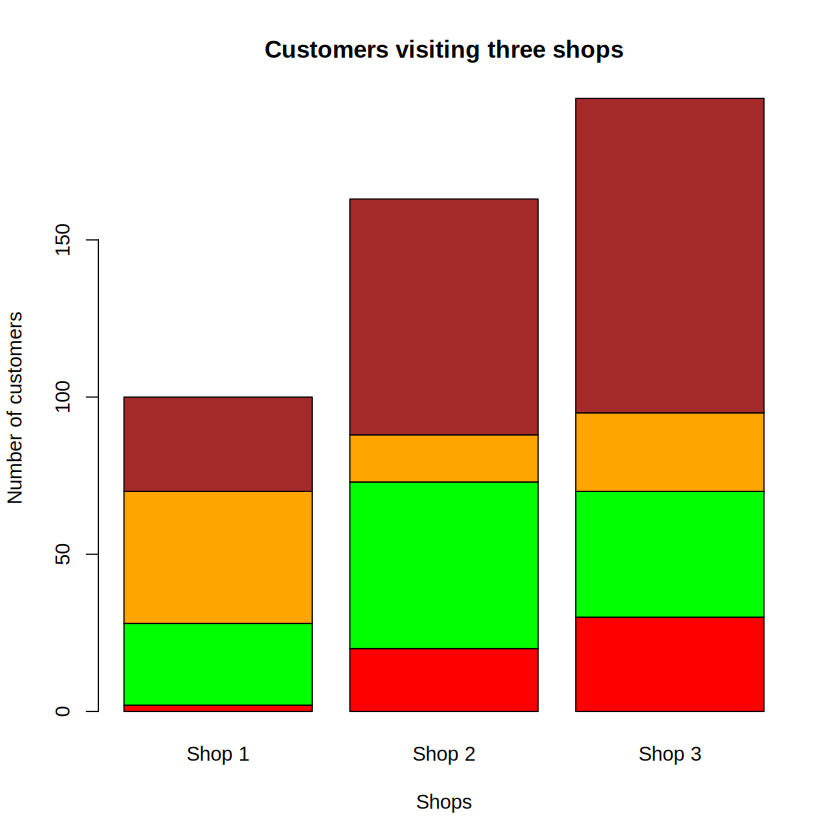

In [3]:
# Add labels, axis titles, and component colours
barplot(
  cust,
  names.arg = c("Shop 1", "Shop 2", "Shop 3"),
  xlab = "Shops",
  ylab = "Number of customers",
  col = c("red", "green", "orange", "brown"),
  main = "Customers visiting three shops"
)

## Lecture 50 — Pie diagram

`pie(x)` draws a pie chart. For categorical data, use `pie(table(x))` so that each category's frequency determines its slice size.

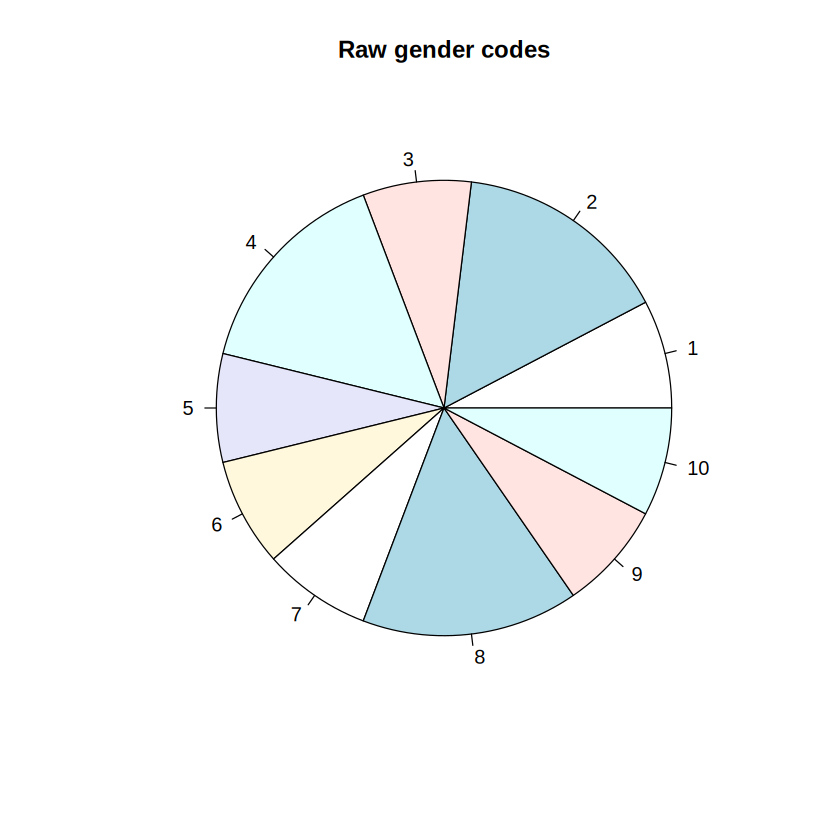

In [4]:
# Gender example from the notes: 1 = male, 2 = female
gender <- c(1, 2, 1, 2, 1, 1, 1, 2, 1, 1)

# The raw numeric vector gives a slice for each observation
pie(gender, main = "Raw gender codes")

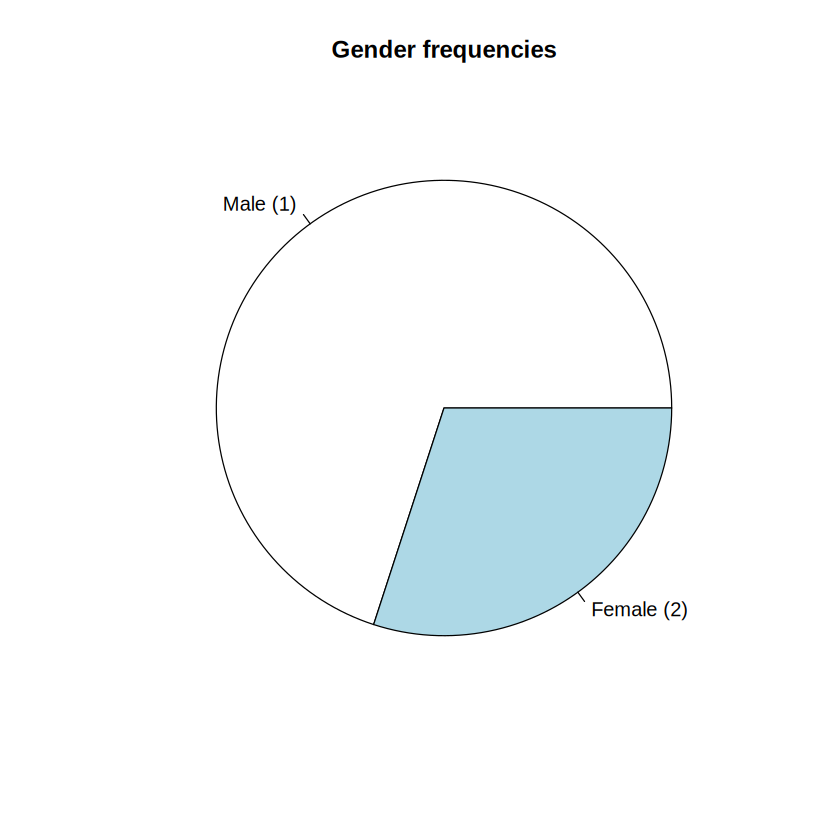

In [5]:
# Correct frequency-based pie chart
pie(table(gender), main = "Gender frequencies",
    labels = c("Male (1)", "Female (2)"))

In [6]:
# Pizza delivery directions: 1 = East, 2 = West, 3 = Central
direction <- c(
  1,1,2,1,2,3,2,2,3,3,3,1,2,3,2,2,3,1,1,3,3,1,2,1,3,
  3,3,2,2,2,2,1,2,2,1,1,1,3,2,2,1,2,3,2,2,1,2,3,3,2,
  1,2,2,3,1,1,2,1,2,3,2,3,2,2,3,1,2,3,3,3,2,1,1,1,2,
  1,1,2,1,2,3,3,1,2,3,3,2,1,2,3,2,1,3,2,2,2,2,3,2,2
)

length(direction)   # should be 100
table(direction)

[1] 100

direction
 1  2  3 
28 43 29 

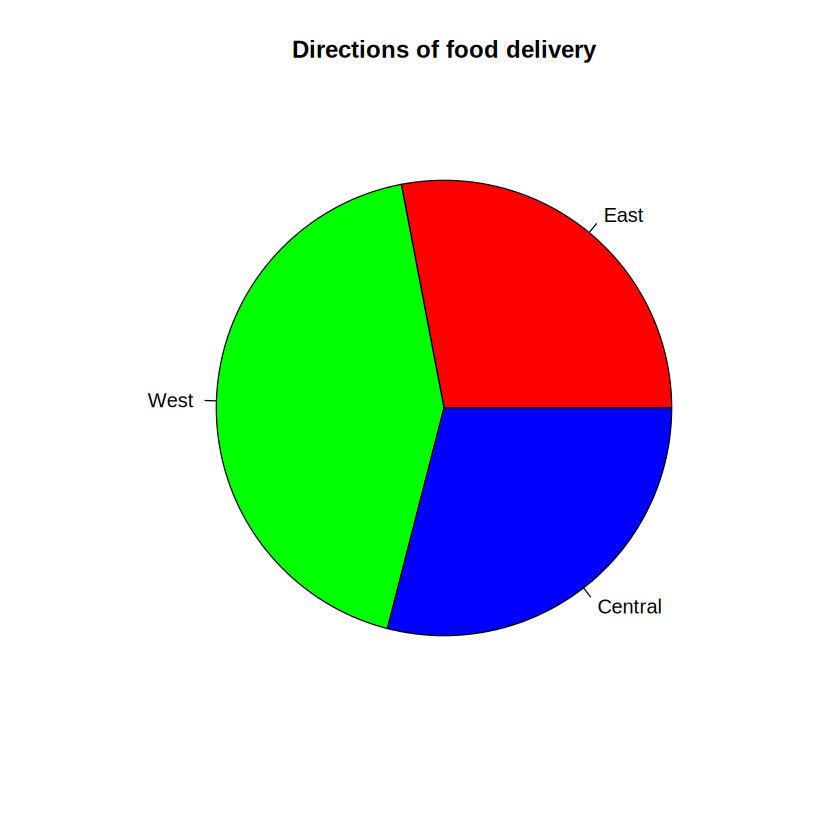

In [7]:
# Pie chart with colours and a main title
pie(
  table(direction),
  col = c("red", "green", "blue"),
  main = "Directions of food delivery",
  labels = c("East", "West", "Central")
)

## Lecture 50 — Combining graphics with `par()`

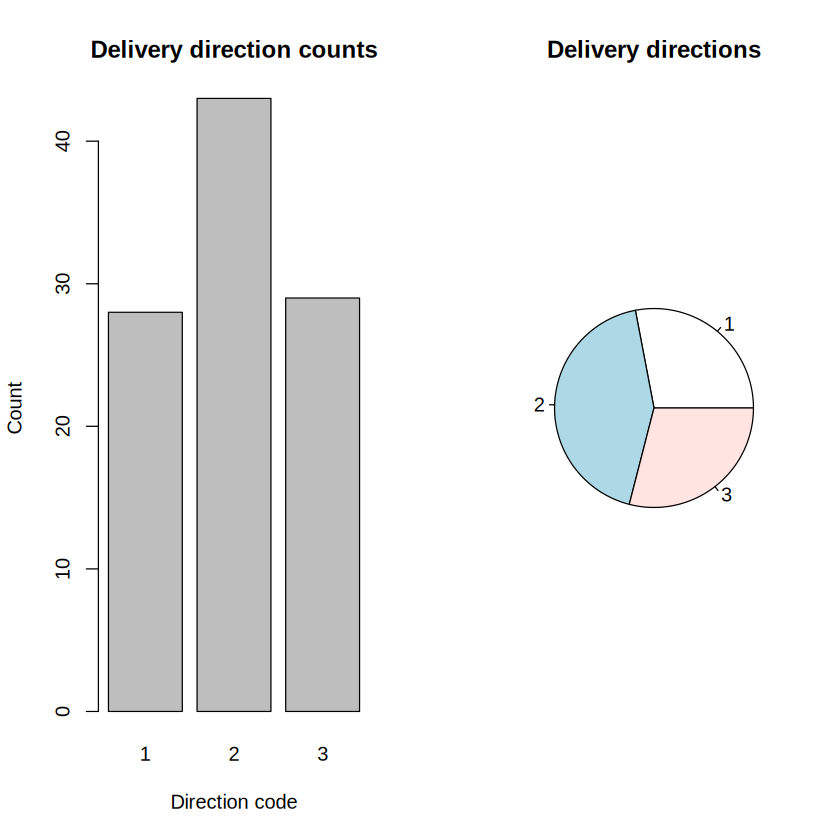

In [8]:
# Two plots side by side
par(mfrow = c(1, 2))
barplot(table(direction), main = "Delivery direction counts",
        xlab = "Direction code", ylab = "Count")
pie(table(direction), main = "Delivery directions")

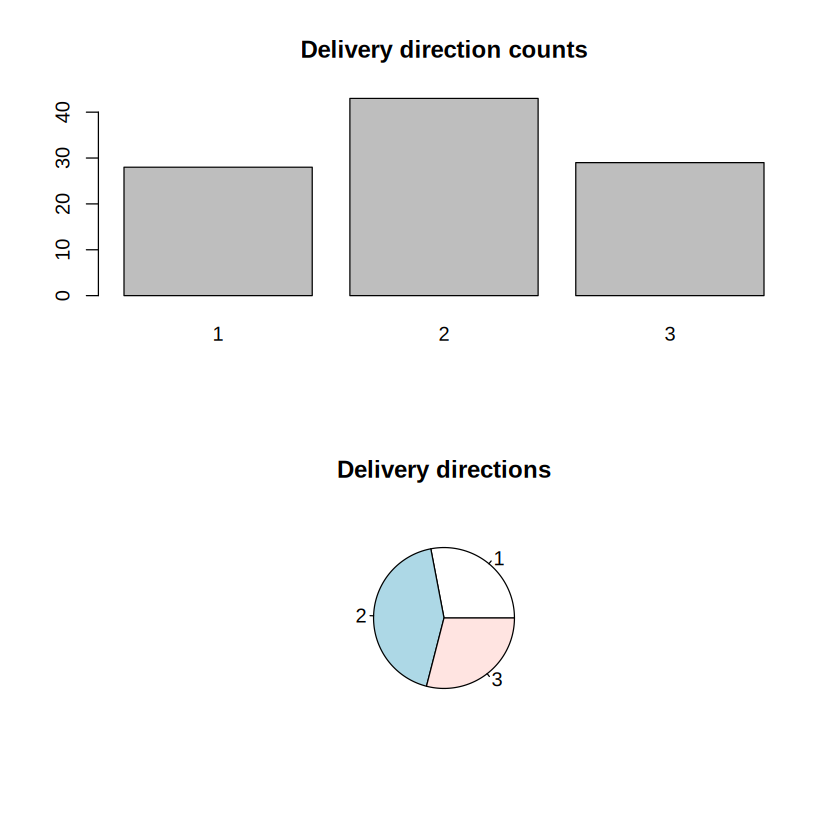

In [9]:
# Two plots one above the other
par(mfrow = c(2, 1))
barplot(table(direction), main = "Delivery direction counts")
pie(table(direction), main = "Delivery directions")

# Reset plotting layout to one panel
par(mfrow = c(1, 1))

## Lecture 51 — Histogram

A histogram groups continuous numeric data into intervals. `hist(x)` shows frequencies; `hist(x, freq = FALSE)` shows density. Options such as `main`, `col`, `xlab`, `xlim`, and `ylim` customize the plot.

In [10]:
height <- c(
  166,125,130,142,147,159,159,147,165,156,149,164,137,166,135,142,
  133,136,127,143,165,121,142,148,158,146,154,157,124,125,158,159,
  164,143,154,152,141,164,131,152,152,161,143,143,139,131,125,145,
  140,163
)
length(height)  # 50 observations

[1] 50

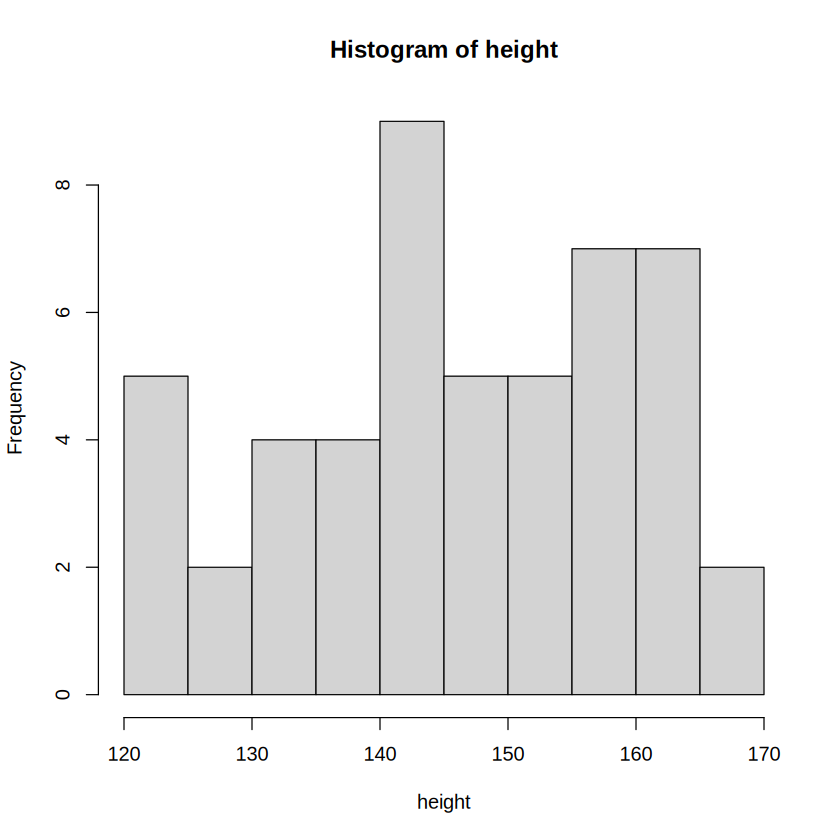

In [11]:
# Basic histogram
hist(height)

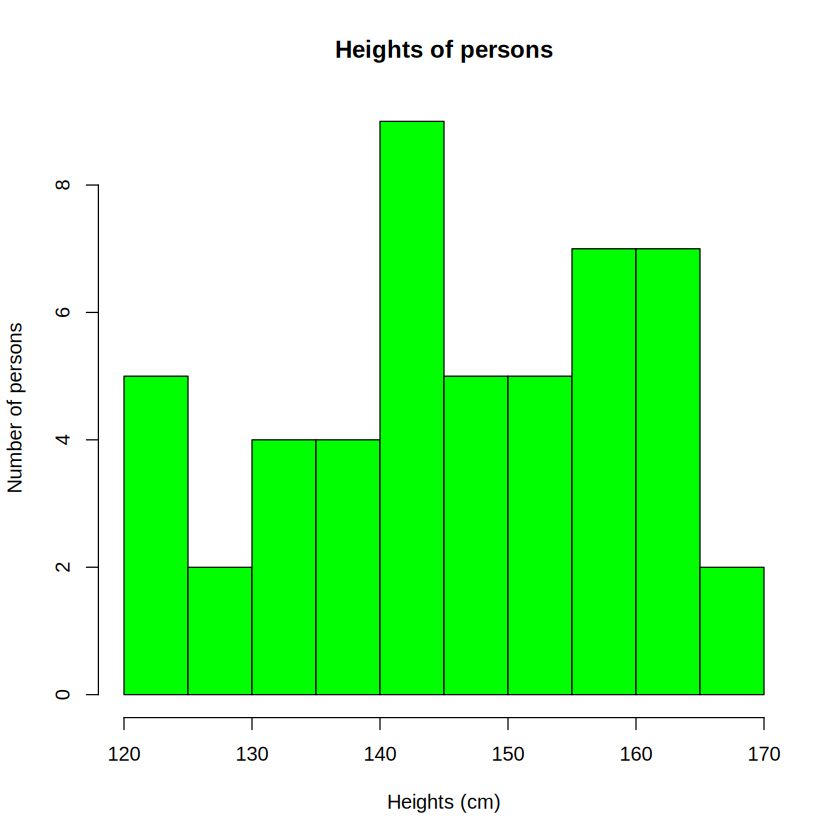

In [12]:
# Add title, bar colour, and axis labels
hist(height,
     main = "Heights of persons",
     col = "green",
     xlab = "Heights (cm)",
     ylab = "Number of persons")

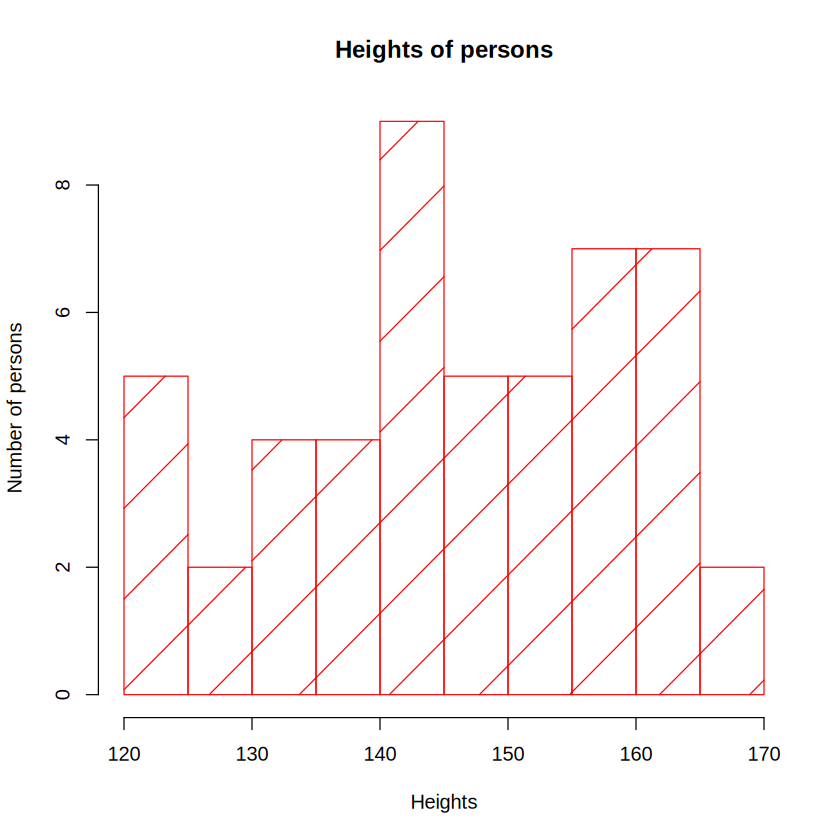

In [13]:
# Histogram with shading density
hist(height, main = "Heights of persons", col = "red",
     xlab = "Heights", ylab = "Number of persons",
     density = 2)

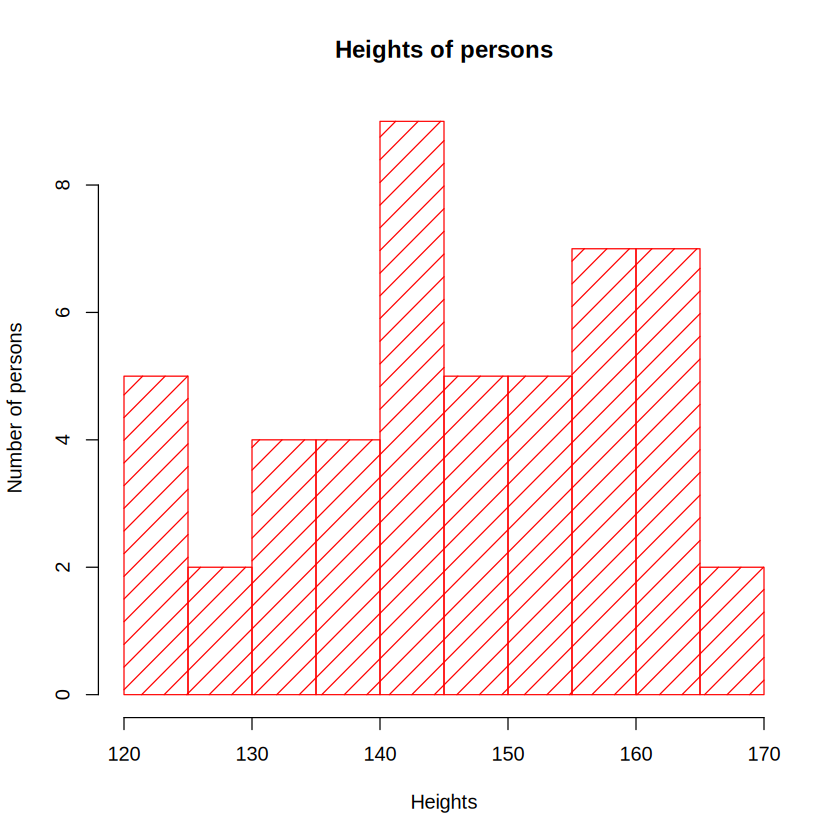

In [14]:
# Increase shading density
hist(height, main = "Heights of persons", col = "red",
     xlab = "Heights", ylab = "Number of persons",
     density = 8)

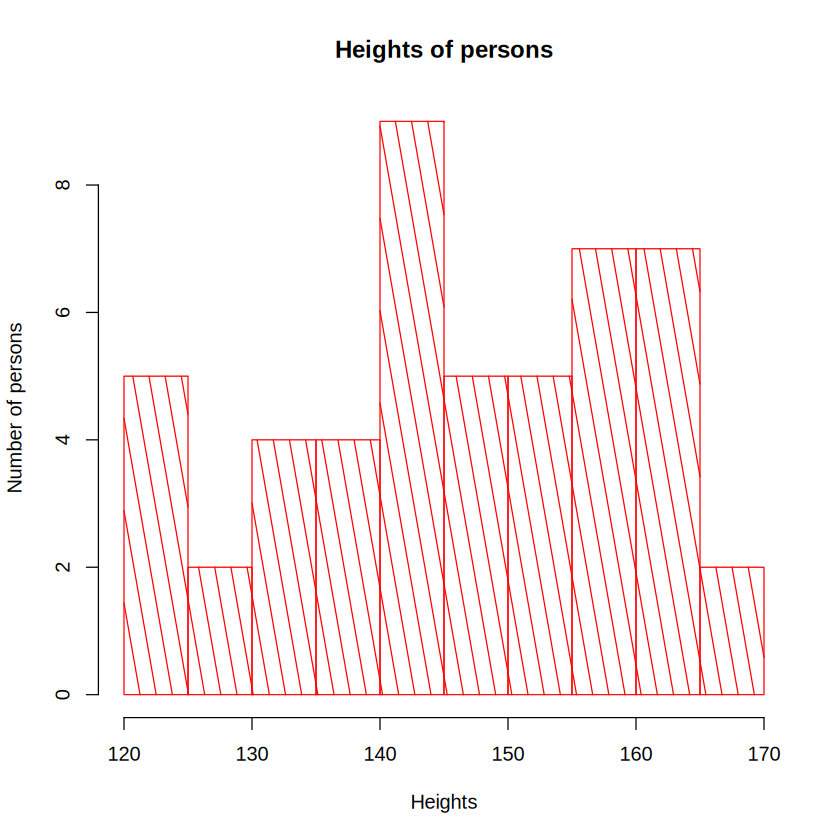

In [15]:
# Change shading angle
hist(height, main = "Heights of persons", col = "red",
     xlab = "Heights", ylab = "Number of persons",
     density = 8, angle = 100)

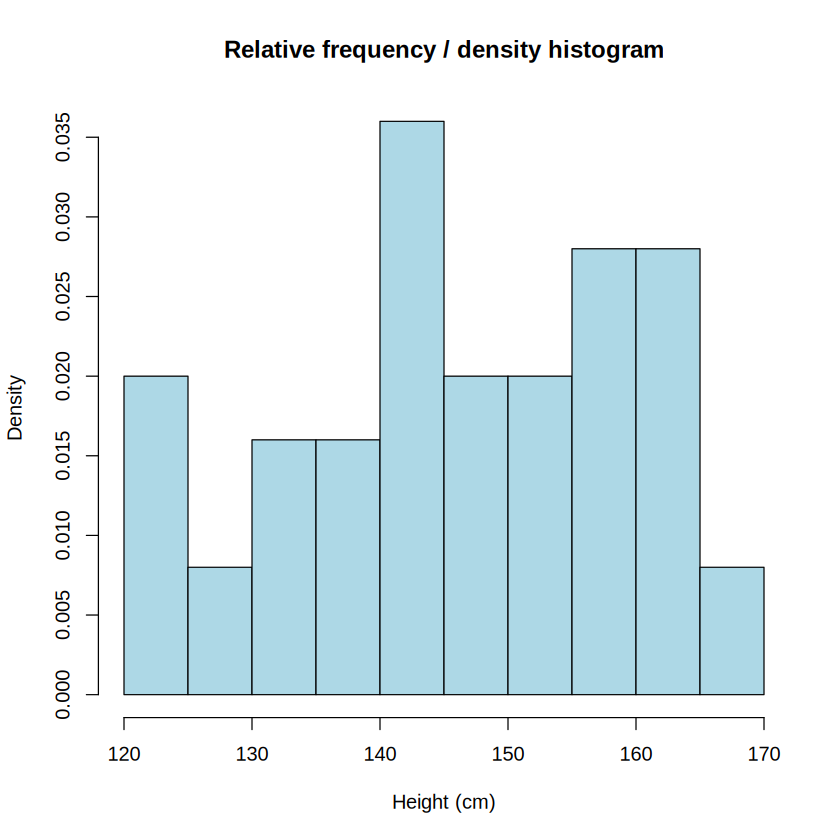

In [16]:
# Relative-frequency/density histogram
hist(height, freq = FALSE,
     main = "Relative frequency / density histogram",
     xlab = "Height (cm)", col = "lightblue")

## Lecture 52 — Bivariate scatter plots

The paired data in the notes record 20 students' weekly study hours and marks. `plot(x, y)` draws a scatter plot. The `type` options shown in the notes are: `p` points, `l` lines, `b` both, `c` lines part only, `o` overplotted points and lines, `s` stair steps, and `h` vertical high-density lines.

In [17]:
marks <- c(337,316,327,340,374,330,352,353,370,380,
           384,398,413,428,430,438,439,479,460,450)
hours <- c(23,25,26,27,30,26,29,32,33,34,
           35,38,39,42,43,44,45,46,44,41)

length(hours)
length(marks)

[1] 20

[1] 20

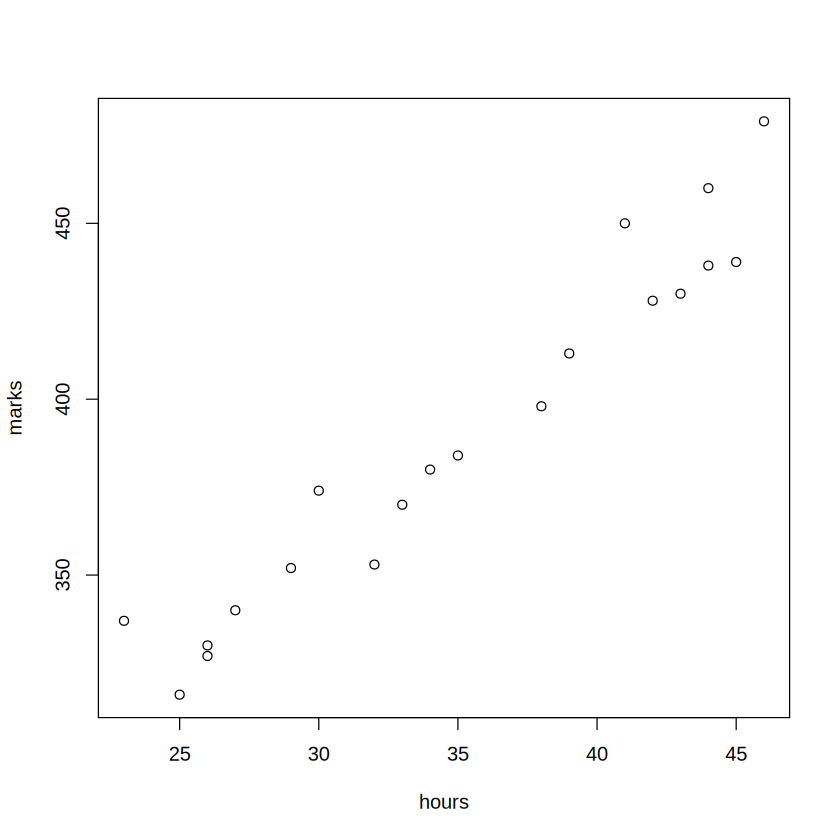

In [18]:
# Default scatter plot
plot(hours, marks)

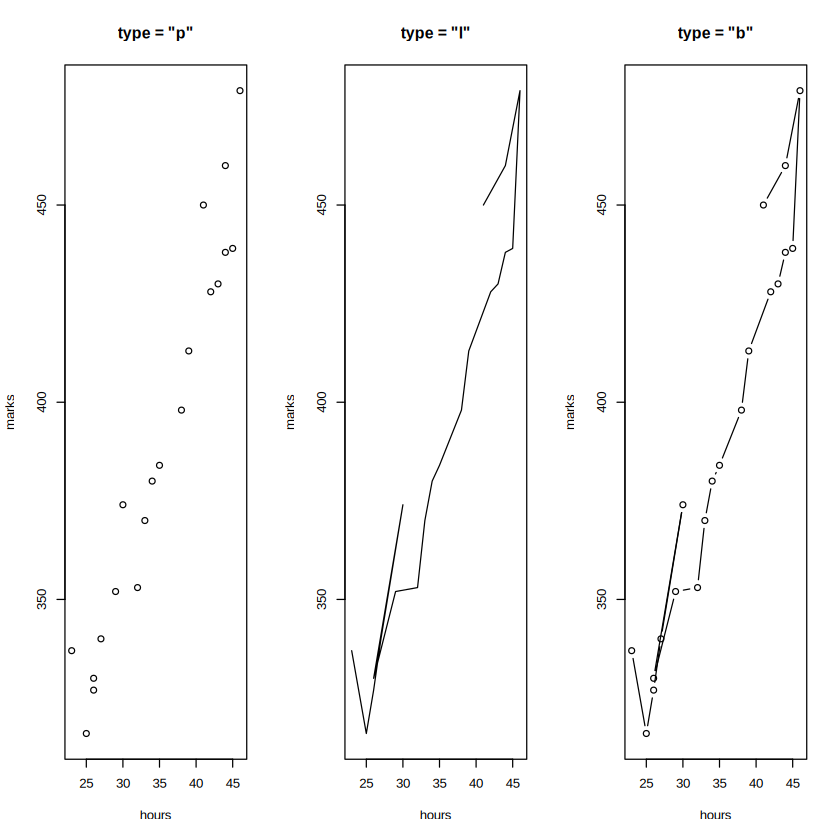

In [19]:
# Points, lines, and both points and lines
par(mfrow = c(1, 3))
plot(hours, marks, type = "p", main = 'type = "p"')
plot(hours, marks, type = "l", main = 'type = "l"')
plot(hours, marks, type = "b", main = 'type = "b"')
par(mfrow = c(1, 1))

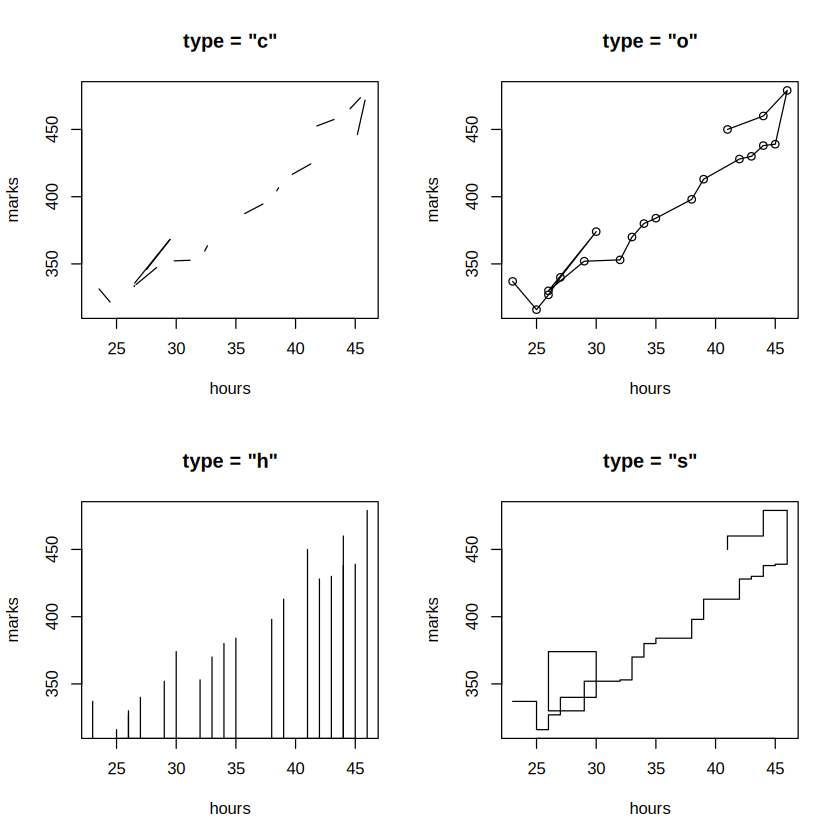

In [20]:
# Other plot types from the lecture
par(mfrow = c(2, 2))
plot(hours, marks, type = "c", main = 'type = "c"')
plot(hours, marks, type = "o", main = 'type = "o"')
plot(hours, marks, type = "h", main = 'type = "h"')
plot(hours, marks, type = "s", main = 'type = "s"')
par(mfrow = c(1, 1))

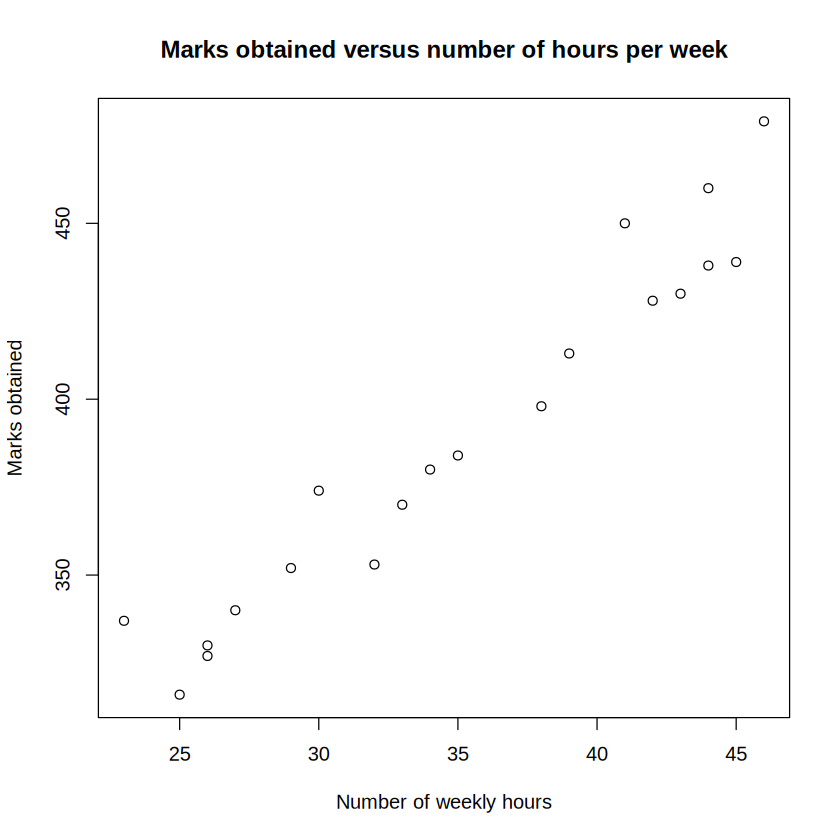

In [21]:
# Label axes and add a title
plot(hours, marks,
     xlab = "Number of weekly hours",
     ylab = "Marks obtained",
     main = "Marks obtained versus number of hours per week")

## Lecture 52 — Matrix scatter plot with `pairs()`

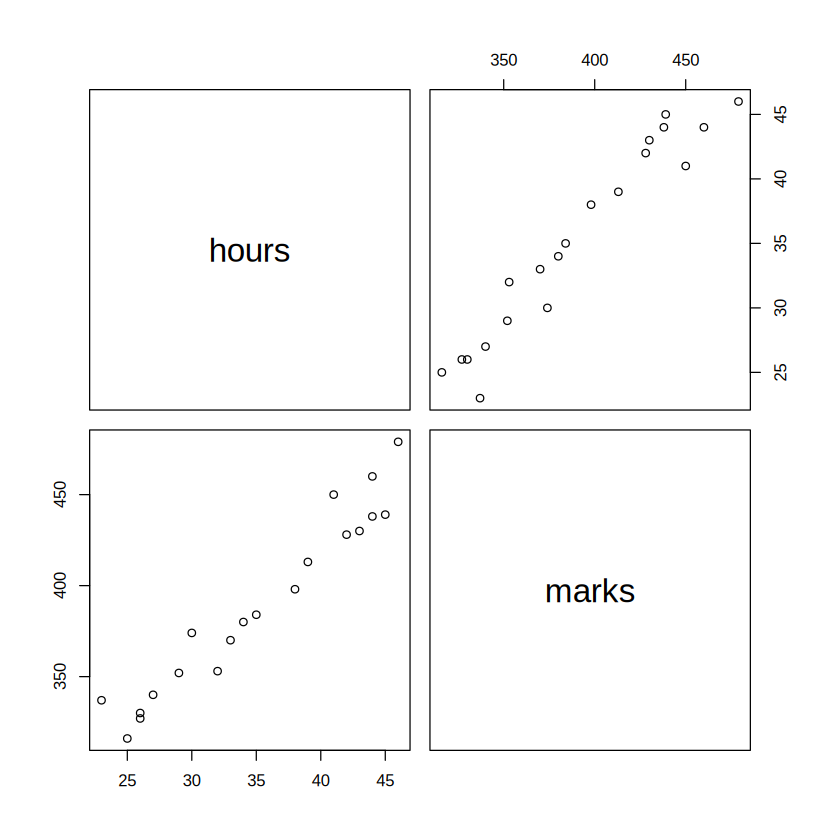

In [22]:
pairs(cbind(hours, marks))

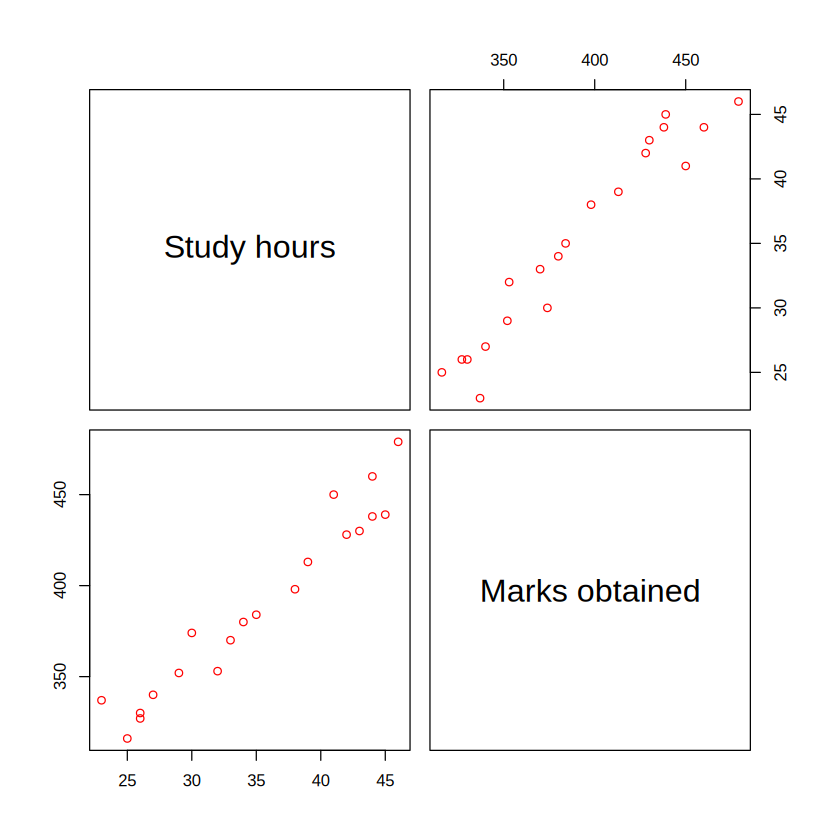

In [23]:
pairs(cbind(hours, marks),
      labels = c("Study hours", "Marks obtained"),
      col = "red")

## Lecture 52 — Scatter plot with a smooth curve

`scatter.smooth()` draws a scatter plot and a locally weighted LOESS smooth curve. `span` controls smoothness and `degree` controls the local polynomial degree.

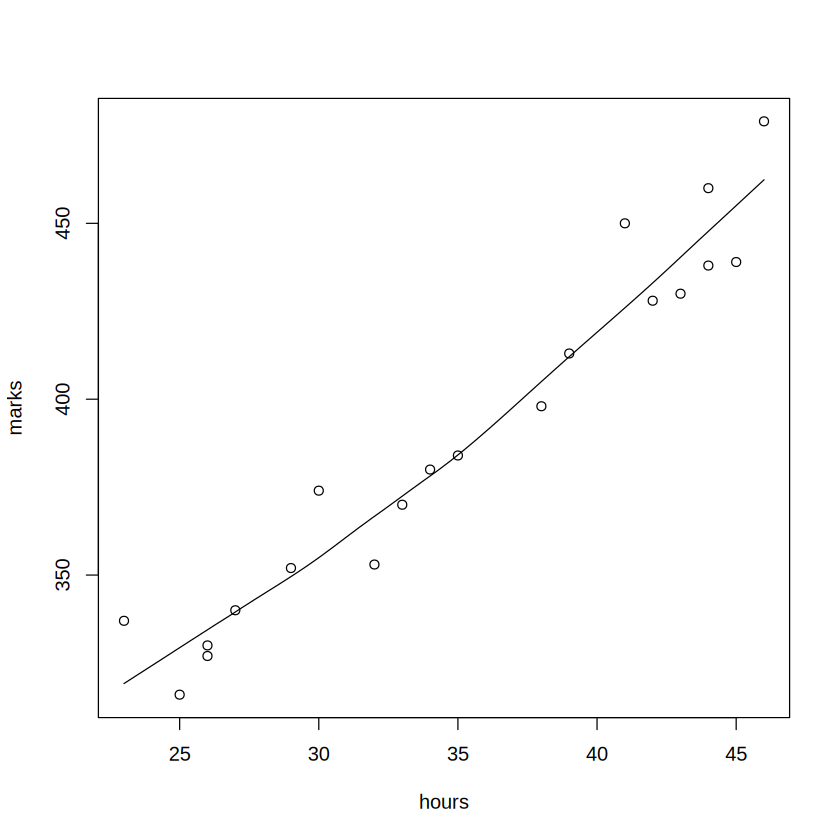

In [24]:
scatter.smooth(hours, marks)

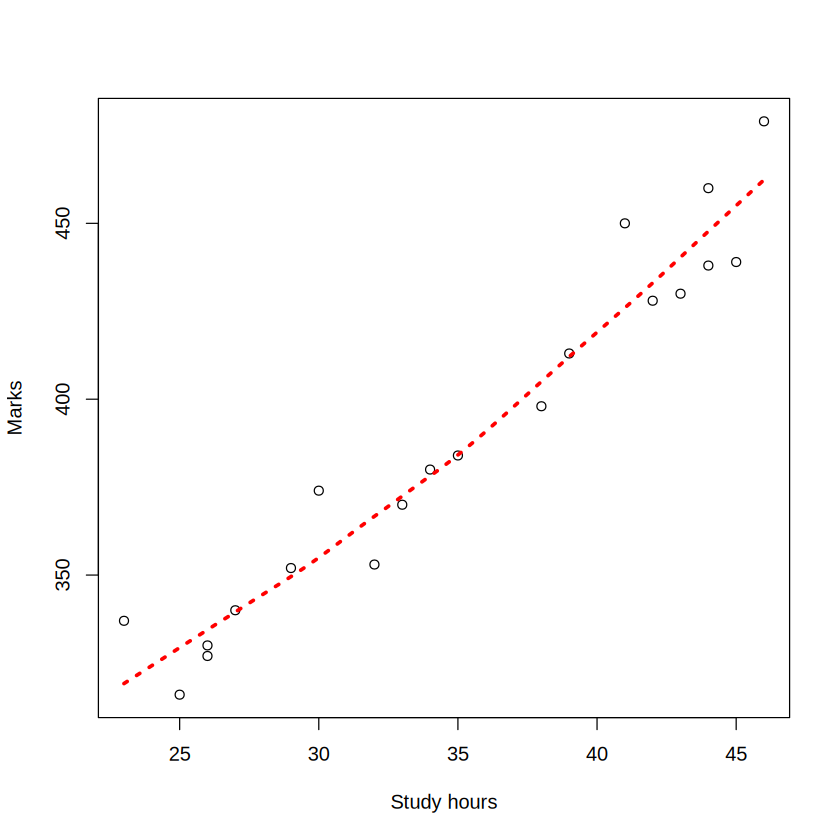

In [25]:
# Customize the smooth line as shown in the notes
scatter.smooth(hours, marks,
               lpars = list(col = "red", lwd = 3, lty = 3),
               xlab = "Study hours",
               ylab = "Marks")

## Lecture 52 — Three-dimensional scatter plot

The notes use the `scatterplot3d` package. Install it if needed, then load it. In an R Colab runtime, package installation may take a short while.

In [26]:
if (!requireNamespace("scatterplot3d", quietly = TRUE)) {
  install.packages("scatterplot3d", repos = "https://cloud.r-project.org")
}
library(scatterplot3d)

height3 <- c(100, 125, 145, 160, 170)
weight <- c(30, 35, 50, 65, 70)
age <- c(10, 15, 20, 30, 35)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



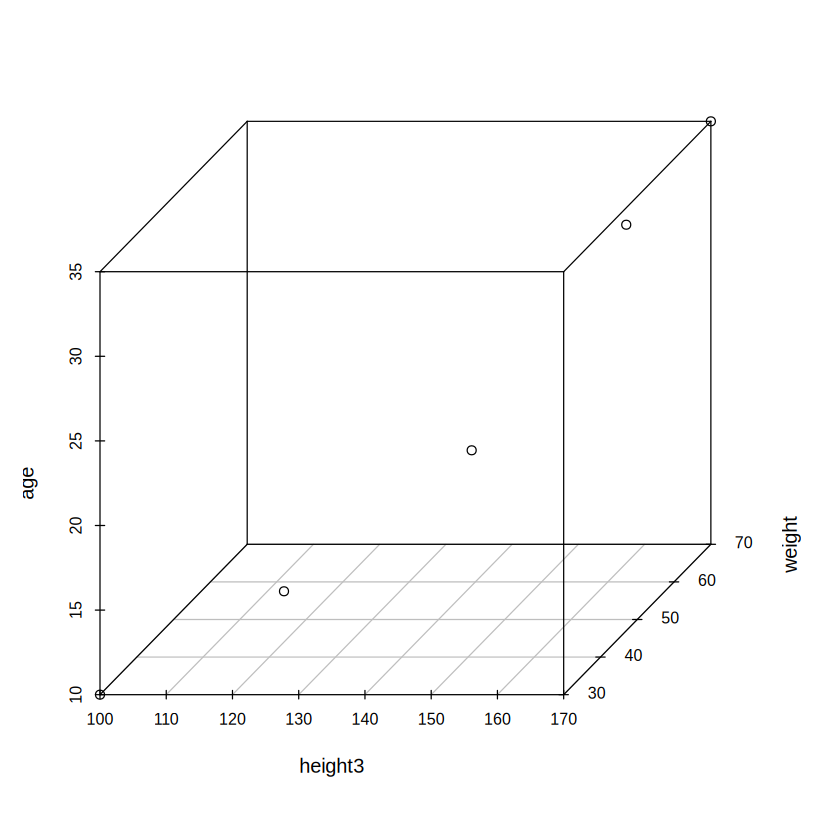

In [27]:
# Basic 3D scatter plot
scatterplot3d(height3, weight, age)

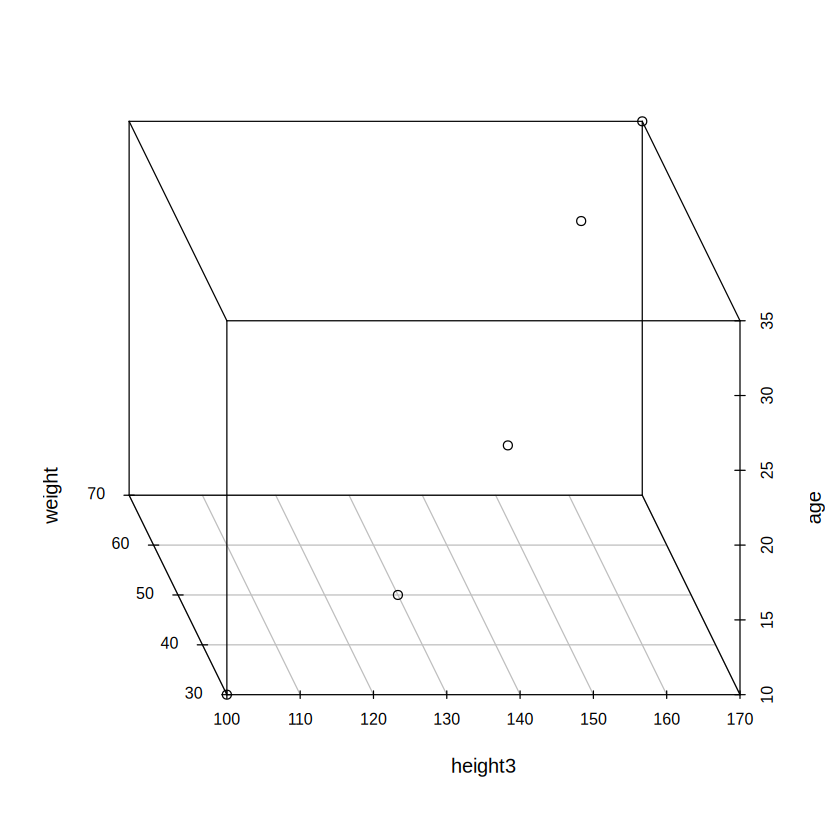

In [28]:
# Change viewing angle
scatterplot3d(height3, weight, age, angle = 120)

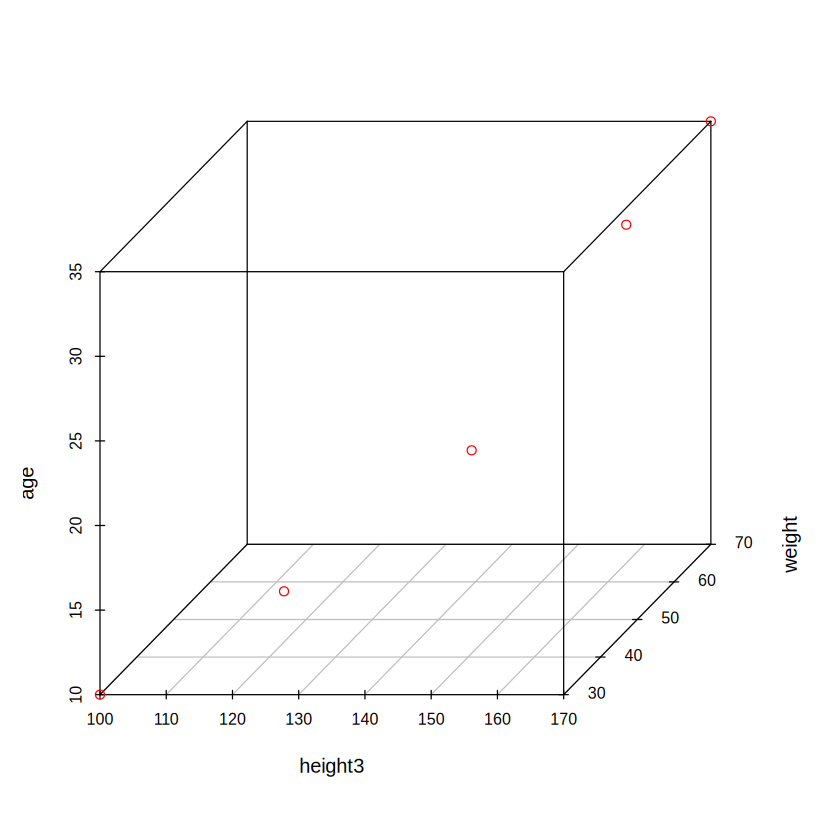

In [29]:
# Change point colour
scatterplot3d(height3, weight, age, color = "red")

## Lecture 52 — Other graphics functions

The notes list these additional functions:
- `contour()` — contour lines
- `dotchart()` — dot chart
- `image()` — colour representation of a third dimension
- `mosaicplot()` — plot for categorical contingency tables
- `persp()` — perspective surface over the x-y plane

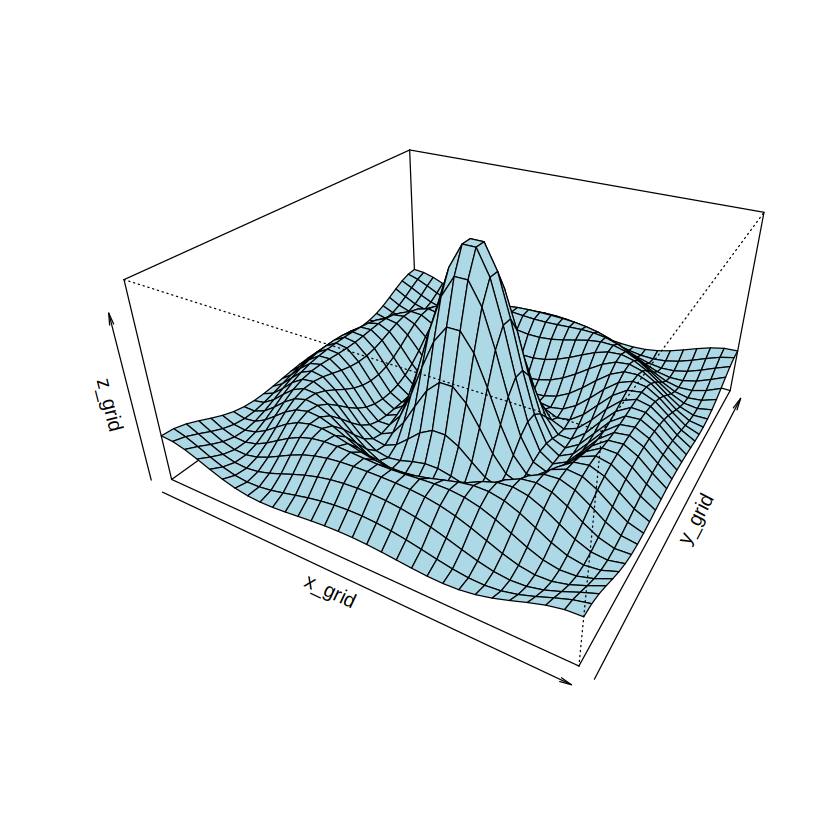

In [30]:
# Perspective surface example from the notes
x_grid <- seq(-10, 10, length.out = 30)
y_grid <- x_grid

f_surface <- function(x, y) {
  r <- sqrt(x^2 + y^2)
  10 * sin(r) / r
}

z_grid <- outer(x_grid, y_grid, f_surface)
z_grid[is.na(z_grid)] <- 1

persp(x_grid, y_grid, z_grid,
      theta = 30, phi = 30, expand = 0.5,
      col = "lightblue")

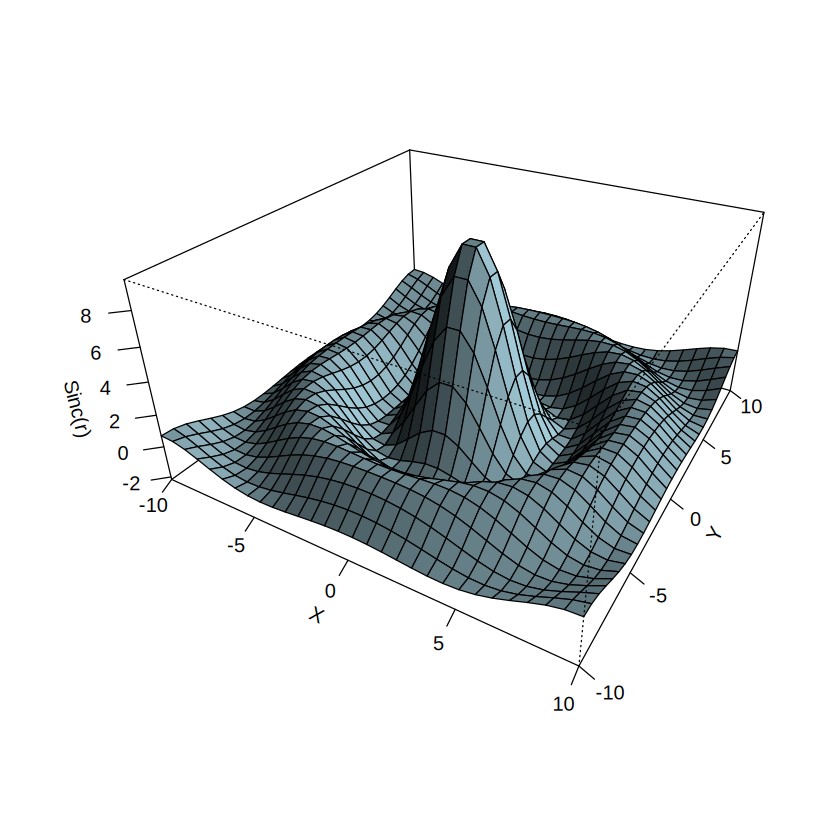

In [31]:
# Detailed perspective surface
persp(x_grid, y_grid, z_grid,
      theta = 30, phi = 30, expand = 0.5,
      col = "lightblue", ltheta = 120, shade = 0.75,
      ticktype = "detailed",
      xlab = "X", ylab = "Y", zlab = "Sinc(r)")

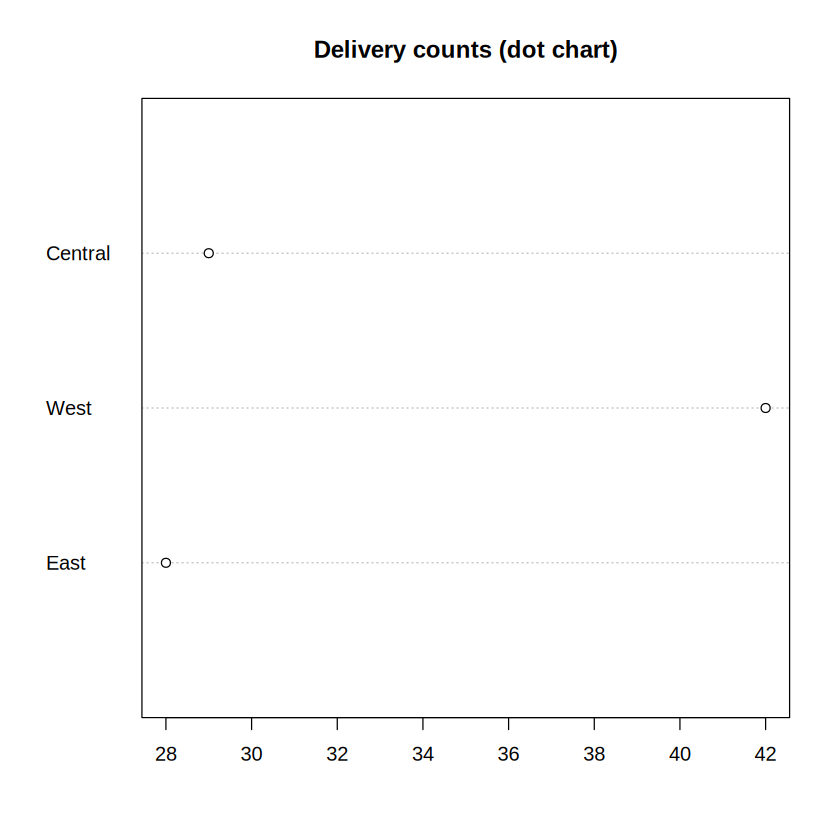

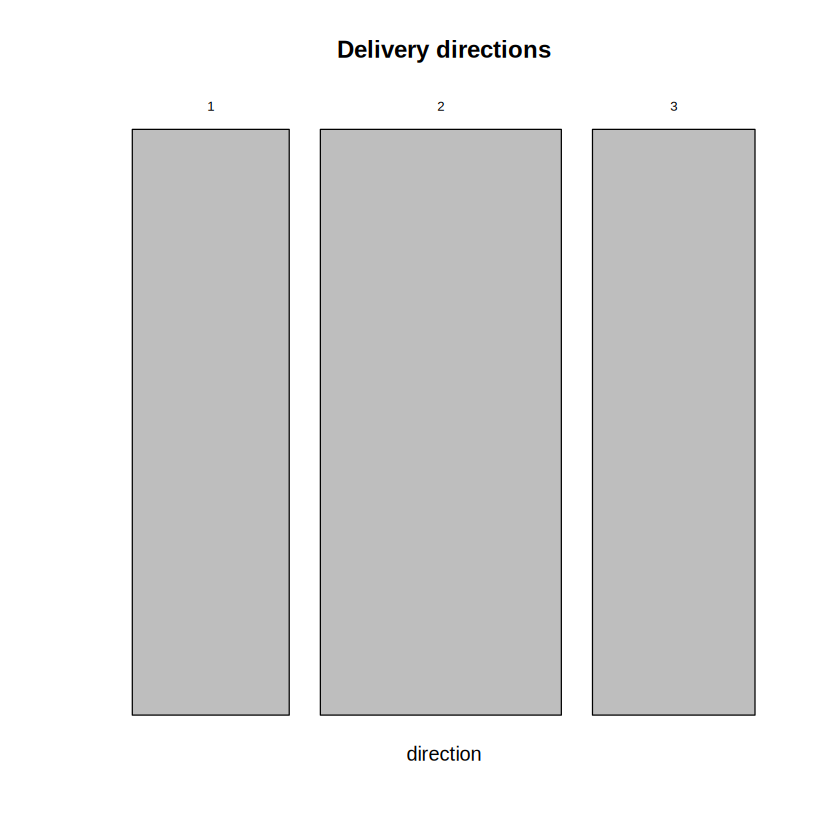

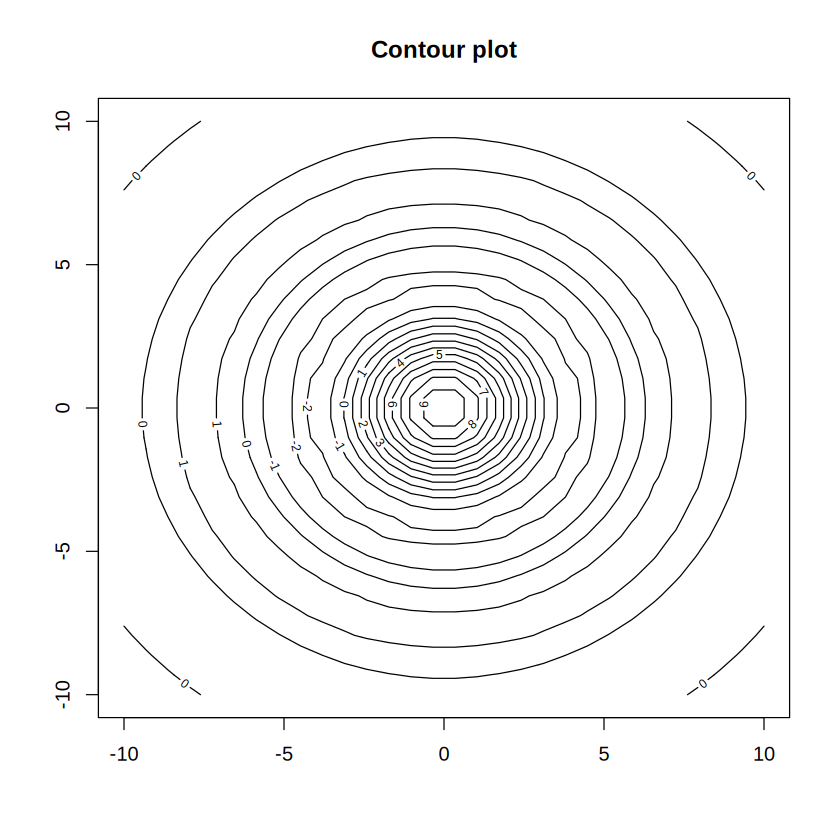

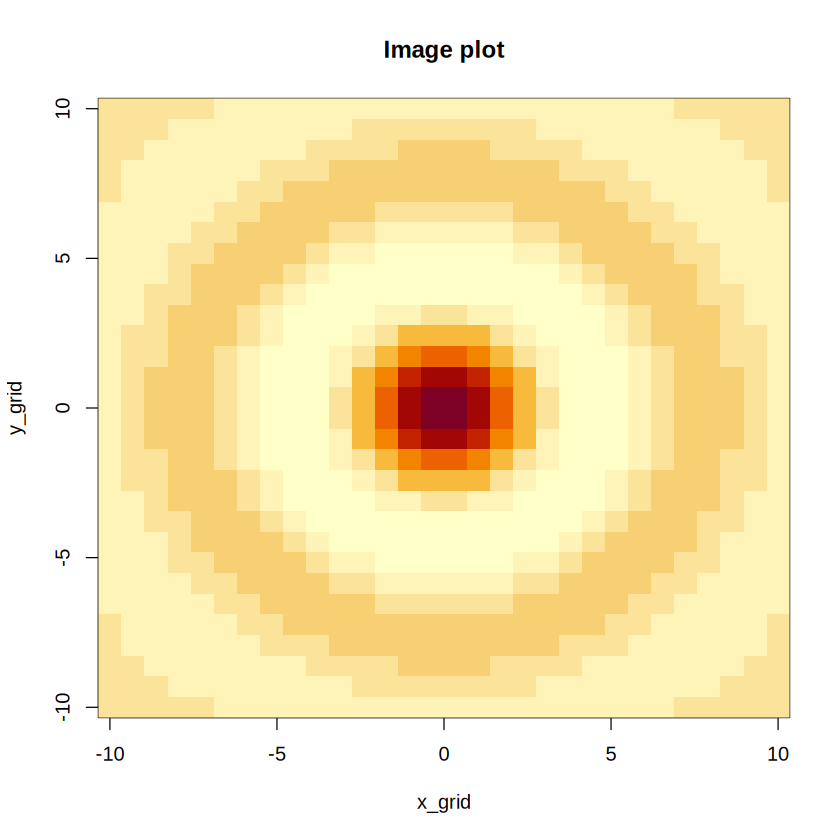

In [32]:
# Extra function examples listed in the lecture
dotchart(c(28, 42, 29), labels = c("East", "West", "Central"),
         main = "Delivery counts (dot chart)")
mosaicplot(table(direction), main = "Delivery directions")
contour(x_grid, y_grid, z_grid, main = "Contour plot")
image(x_grid, y_grid, z_grid, main = "Image plot")

## Lecture 53 — Programming tips from the notes

- A program is a sequence of instructions intended to produce an outcome from inputs.
- Define the objective, inputs, outputs, and the types of variables before coding.
- In R, a function is defined with `function(...)`.
- Use comments (`#`), readable variable names, and initialize variables.
- The notes recommend vector/matrix operations where possible because loops can be slower.

## Programming Example 1 — Ratios of sums of squares

Given numeric vectors `x` and `y`, compute:

- \(g = \\frac{\\sum x_i^2}{\\sum y_i^2}\)
- \(h = \\sum (x_i/y_i)^2\)

The notebook includes a loop-based function (matching the lecture's approach) and a vectorized alternative.

In [33]:
example1 <- function(x, y) {
  if (length(x) != length(y)) {
    stop("x and y must have the same length")
  }

  n <- length(x)
  x_sq <- numeric(n)
  y_sq <- numeric(n)
  ratio_sq <- numeric(n)

  for (i in 1:n) {
    x_sq[i] <- x[i]^2
    y_sq[i] <- y[i]^2
    ratio_sq[i] <- (x[i] / y[i])^2
  }

  g <- sum(x_sq) / sum(y_sq)
  h <- sum(ratio_sq)

  cat("The value of g and h are", g, "and", h, "respectively\n")
  invisible(c(g = g, h = h))
}

In [34]:
# Example 1: first input from the notes
x <- c(10, 20, 30)
y <- c(1, 2, 3)
example1(x, y)

The value of g and h are 100 and 300 respectively


In [35]:
# Example 1: second input from the notes
x <- c(67, 87, 26, 85, 6, 45)
y <- c(54, 64, 22, 94, 20, 88)
example1(x, y)

The value of g and h are 0.8996568 and 5.953203 respectively


In [36]:
# Alternative vectorized approach from the notes
example1_vectorized <- function(x, y) {
  if (length(x) != length(y)) stop("x and y must have the same length")
  g <- sum(x^2) / sum(y^2)
  h <- sum((x / y)^2)
  c(g = g, h = h)
}

example1_vectorized(c(10, 20, 30), c(1, 2, 3))

g   h 
100 300

## Programming Example 2 — Function calling another function

The notes define:

- \(g(x,y) = (x + \\ln(y))/y\)
- \(f(x,y) = \\frac{g(x,y)^2}{5 + g(x,y)^3}\\,[\\exp(g(x,y))]^{2/3}\)

Define `g()` first, then define `f()` to call `g()`.

In [37]:
g <- function(x, y) {
  (x + log(y)) / y
}

f <- function(x, y) {
  gx <- g(x, y)
  ((gx^2) / (5 + gx^3)) * (exp(gx))^(2/3)
}

In [38]:
# Example values from the notes
f(10, 20)
f(1896, 23454)

[1] 0.1234539

[1] 0.001394291

In [39]:
# Check the intermediate function too
g(10, 20)

[1] 0.6497866

## Programming Example 3 — Piecewise function and plotting

The notes define the piecewise function:

- if \(x > 0\): \(f(x) = \\exp((x + \\ln(1+x^3))/x^2)\)
- if \(x = 0\): \(f(x) = 10\)
- if \(x < 0\): \(f(x) = (2+x^3)/x\)

Then evaluate it on a sequence from -1 to 5 in increments of 0.2 and plot the result with a line.

In [40]:
f_piecewise <- function(x) {
  if (x > 0) {
    exp((x + log(1 + x^3)) / x^2)
  } else if (x == 0) {
    10
  } else {
    (2 + x^3) / x
  }
}

In [41]:
# Test values shown in the lecture
f_piecewise(123)
f_piecewise(-123)
f_piecewise(0)
f_piecewise(8)
f_piecewise(-4)

[1] 1.009126

[1] 15128.98

[1] 10

[1] 1.249201

[1] 15.5

,x,y
,<dbl>,<dbl>
1,-1.0,-1.000000
2,-0.8,-1.860000
3,-0.6,-2.973333
4,-0.4,-4.840000
5,-0.2,-9.960000
6,0.0,10.000000


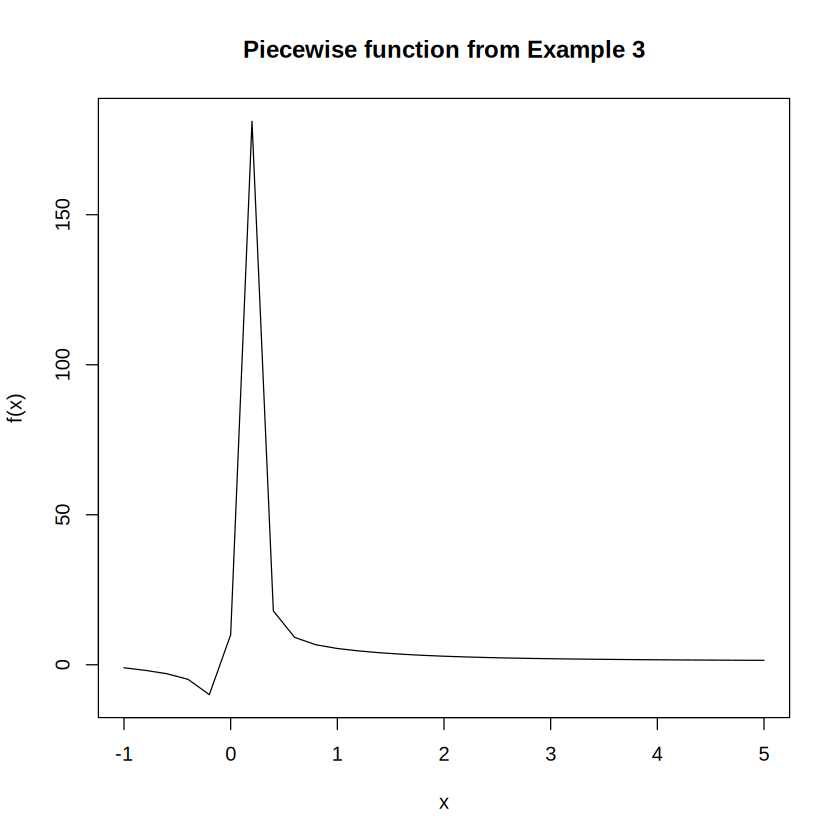

In [42]:
# Generate x values and corresponding function values
plot_piecewise <- function() {
  x_values <- seq(-1, 5, by = 0.2)
  y_values <- numeric(length(x_values))

  for (i in seq_along(x_values)) {
    y_values[i] <- f_piecewise(x_values[i])
  }

  plot(x_values, y_values, type = "l",
       xlab = "x", ylab = "f(x)",
       main = "Piecewise function from Example 3")
  invisible(data.frame(x = x_values, y = y_values))
}

piecewise_data <- plot_piecewise()
head(piecewise_data)